In [32]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


In [33]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, OLD_DATASETS, NEW_DATASETS, ALL_DATASETS, NUM_SEEDS, NUM_REPS
from smac_hpo.evaluation.utils import SINGLE_COLUMN_WIDTH, PANEL_HEIGHT, facet_aspect, set_publication_style
set_publication_style()

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LATEX_DIR = pathlib.Path("latex")
LATEX_DIR.mkdir(parents=True, exist_ok=True )

In [34]:
HYPERPARAMETERS = {
    "FSD": [
        "model",
        "threshold",
        "window",
        "batch_size"
    ],
    "textClust": [
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "term_fading",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
    "embClust": [
        "model", 
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
}
HYPERPARAMETERS_FLATTENED = list(set(param for params in HYPERPARAMETERS.values() for param in params))

In [35]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

In [36]:
config_performance = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()

config_performance_old_datasets = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(OLD_DATASETS)].copy()

for _, group in config_performance.groupby(["dataset"]):
    config_performance.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values

for _, group in config_performance_old_datasets.groupby(["dataset"]):
    config_performance_old_datasets.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


config_performance = (
    config_performance
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

config_performance_old_datasets = (
    config_performance_old_datasets
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

display(config_performance)
display(config_performance_old_datasets)

,config_id,algorithm,sigma,threshold_momentum,model,time_gap,clean_interval,min_weight,window,radius,min_num_mc,use_heuristic,adaptive_threshold,decay_rate,threshold,term_fading,batch_size,cluster_interval,adj_mutual_info_final,avg_throughput
0,FSD_best_config_loo_none_seed_1.json[0],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,125.0,NaN,NaN,NaN,NaN,NaN,0.500000,NaN,8.0,NaN,0.680219,0.645520
1,FSD_best_config_loo_none_seed_1.json[1],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,116.0,NaN,NaN,NaN,NaN,NaN,0.514959,NaN,9.0,NaN,0.497164,0.962960
2,FSD_best_config_loo_none_seed_1.json[2],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,0.306805,NaN,25.0,NaN,0.319218,0.976516
3,FSD_best_config_loo_none_seed_1.json[3],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,0.584279,NaN,3.0,NaN,0.716483,0.642982
4,FSD_best_config_loo_none_seed_1.json[4],FSD,NaN,NaN,minishlab_8M,NaN,NaN,NaN,78.0,NaN,NaN,NaN,NaN,NaN,0.586306,NaN,29.0,NaN,0.474775,0.957480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,0.263364,0.234695,NaN,NaN,400.0,7.137730,NaN,NaN,2.0,0.0,1.0,0.000236,NaN,1.0,NaN,4888.0,0.627966,0.920698
142,textClust_best_config_loo_none_seed_9.json[5],textClust,0.266890,0.079436,NaN,NaN,227.0,1.938501,NaN,NaN,9.0,0.0,1.0,0.021127,NaN,1.0,NaN,4925.0,0.664263,0.951646
143,textClust_best_config_loo_none_seed_9.json[6],textClust,0.121910,0.025919,NaN,NaN,114.0,3.097142,NaN,NaN,2.0,0.0,1.0,0.011202,NaN,0.0,NaN,4953.0,0.646849,0.811976
144,textClust_best_config_loo_none_seed_9.json[7],textClust,0.145887,0.010312,NaN,NaN,116.0,4.407335,NaN,NaN,2.0,0.0,1.0,0.011370,NaN,0.0,NaN,4957.0,0.691339,0.821548


,config_id,algorithm,sigma,threshold_momentum,model,time_gap,clean_interval,min_weight,window,radius,min_num_mc,use_heuristic,adaptive_threshold,decay_rate,threshold,term_fading,batch_size,cluster_interval,adj_mutual_info_final,avg_throughput
0,FSD_best_config_loo_none_seed_1.json[0],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,125.0,NaN,NaN,NaN,NaN,NaN,0.500000,NaN,8.0,NaN,0.741515,0.694088
1,FSD_best_config_loo_none_seed_1.json[1],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,116.0,NaN,NaN,NaN,NaN,NaN,0.514959,NaN,9.0,NaN,0.638557,0.955922
2,FSD_best_config_loo_none_seed_1.json[2],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,0.306805,NaN,25.0,NaN,0.477592,0.971194
3,FSD_best_config_loo_none_seed_1.json[3],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,0.584279,NaN,3.0,NaN,0.716279,0.691229
4,FSD_best_config_loo_none_seed_1.json[4],FSD,NaN,NaN,minishlab_8M,NaN,NaN,NaN,78.0,NaN,NaN,NaN,NaN,NaN,0.586306,NaN,29.0,NaN,0.668250,0.962013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,0.263364,0.234695,NaN,NaN,400.0,7.137730,NaN,NaN,2.0,0.0,1.0,0.000236,NaN,1.0,NaN,4888.0,0.762790,0.922767
142,textClust_best_config_loo_none_seed_9.json[5],textClust,0.266890,0.079436,NaN,NaN,227.0,1.938501,NaN,NaN,9.0,0.0,1.0,0.021127,NaN,1.0,NaN,4925.0,0.593075,0.952992
143,textClust_best_config_loo_none_seed_9.json[6],textClust,0.121910,0.025919,NaN,NaN,114.0,3.097142,NaN,NaN,2.0,0.0,1.0,0.011202,NaN,0.0,NaN,4953.0,0.496894,0.757937
144,textClust_best_config_loo_none_seed_9.json[7],textClust,0.145887,0.010312,NaN,NaN,116.0,4.407335,NaN,NaN,2.0,0.0,1.0,0.011370,NaN,0.0,NaN,4957.0,0.527019,0.765395


In [37]:
def prepare_dataset(full_df, algorithm):
    df = full_df.copy()
    df = df[df["algorithm"] == algorithm]

    df = df[["adj_mutual_info_final", "avg_throughput", "config_id"] + HYPERPARAMETERS[algorithm]]
    df = df.dropna(axis=1, how="any")
    
    config_ids = df["config_id"]
    df = df.drop(columns=["config_id"])
    if np.any(df.dtypes == "str"):
        df = pd.get_dummies(df, columns=df.columns[df.dtypes == "str"], drop_first=True)
    df = df.astype(float)

    # Min-max normalization for each hyperparameter
    df = (df - df.min()) / (df.max() - df.min())

    y = df[["adj_mutual_info_final", "avg_throughput"]].values
    X = df.drop(columns=["adj_mutual_info_final", "avg_throughput"])
    X.loc[:, "config_id"] = config_ids
    
    return X, y

In [38]:
from sklearn.model_selection import ParameterGrid
import numpy as np
import smac_hpo.evaluation.evolutionary_clustering as evolutionary_clustering
from sklearn.metrics import silhouette_score
from tqdm import tqdm
from sklearn.decomposition import PCA

def grid_search(X, y, objective_weight=0.5, decision_weight=0.5):
    weights = np.array([objective_weight, decision_weight], dtype=float)
    if np.any(weights < 0) or weights.sum() == 0:
        raise ValueError("Weights must be non-negative and at least one must be positive.")
    weights /= weights.sum()

    X = X.drop(columns=["config_id"]).copy()
    params = {
        "dim": list(range(1,X.shape[1])),
        "n_clusters": list(range(2,10))
    }

    best = None
    best_metric = 0.0

    for param in tqdm(ParameterGrid(params)):
        dim = param["dim"]
        n_clusters = param["n_clusters"]
        
        X_low_dim = PCA(n_components=dim).fit_transform(X)
        
        best_labels = evolutionary_clustering.evolutionary_multi_space_clustering(
            X_low_dim, y,
            generations=500,
            n_clusters=n_clusters,
            random_state=42)
        
        objective_silhouette = silhouette_score(y, best_labels)
        decision_silhouette = silhouette_score(X_low_dim, best_labels)
        objective_score = (objective_silhouette + 1) / 2
        decision_score = (decision_silhouette + 1) / 2
        score_sum = objective_score + decision_score
        mean = 0.0 if score_sum == 0 else 2 * objective_score * decision_score / score_sum
        if mean > best_metric:
            print(f"Found new best: {mean}, {param}")
            best_metric = mean
            best = param
            
    assert best is not None, "No configuration found!"        
    print(f"Best configuration: {best} ({best_metric})")
    return best, best_metric

In [39]:
def evaluate(X,y,best_config):
    X_low_dim = PCA(n_components=best_config["dim"]).fit_transform(X.drop(columns=["config_id"]))
    best_labels = evolutionary_clustering.evolutionary_multi_space_clustering(
        X_low_dim, y,
        generations=500,
        n_clusters=best_config["n_clusters"],
        random_state=42)

    print("Decision-space silhouette:", silhouette_score(X_low_dim, best_labels))
    print("Objective-space silhouette:", silhouette_score(y, best_labels))
    print("Mean silhouette:", (silhouette_score(y, best_labels) + silhouette_score(X_low_dim, best_labels))/2)
    df_config = X.copy()
    df_config["cluster"] = best_labels

    df_performance = pd.DataFrame(y.copy(), columns=["adj_mutual_info_final", "avg_throughput"])
    df = df_config.copy()
    df.loc[:, df_performance.columns] = df_performance.values
    return df

In [40]:
DO_GRID_SEARCH = False

best_configs = {
    "FSD": {'dim': 3, 'n_clusters': 2},
    "embClust" : {'dim': 1, 'n_clusters': 2},
    "textClust" : {'dim': 6, 'n_clusters': 2}
}

result = []
for alg in ["FSD", "embClust", "textClust"]:
    X,y = prepare_dataset(config_performance, alg)
    if DO_GRID_SEARCH:
        best, _ = grid_search(X, y)
    else:
        best = best_configs[alg]
    df = evaluate(X,y,best)
    df["algorithm"] = alg
    result.append(df)
    
cluster_results = pd.concat(result)

cluster_centroids = cluster_results.copy()
cluster_centroids = (
    cluster_centroids.drop(columns="config_id").groupby(["algorithm", "cluster"])
    .mean()   
    .reset_index() 
)
cluster_centroids
    

Decision-space silhouette: 0.40943004717481657
Objective-space silhouette: 0.5816096049732083
Mean silhouette: 0.49551982607401246
Decision-space silhouette: 0.6197309827218555
Objective-space silhouette: 0.37844922880913745
Mean silhouette: 0.49909010576549645
Decision-space silhouette: 0.2954401368423174
Objective-space silhouette: 0.6534694503947288
Mean silhouette: 0.4744547936185231


,algorithm,cluster,threshold,window,batch_size,model_Mihaiii_gte_micro_v4,model_MongoDB,model_NeuML,model_Snowflake,model_intfloat,...,model_sentence_transformers_all_MiniLM_L6_v2,adj_mutual_info_final,avg_throughput,clean_interval,cluster_interval,decay_rate,min_num_mc,adaptive_threshold,use_heuristic,term_fading
0,FSD,0,0.411948,0.321347,0.028376,0.00000,0.00000,0.000000,0.083333,0.000000,...,0.916667,0.884344,0.066379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FSD,1,0.506639,0.385845,0.147783,0.02381,0.02381,0.166667,0.000000,0.047619,...,0.000000,0.420800,0.825352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,embClust,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.095238,0.629911,0.716698,0.579223,0.231781,0.110532,0.275862,1.000000,0.761905,NaN
3,embClust,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.086957,0.320535,0.858767,0.643693,0.460224,0.193299,0.490255,0.782609,0.608696,NaN
4,textClust,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.860993,0.569276,0.438073,0.392386,0.231625,0.156469,1.000000,0.409091,0.727273
5,textClust,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.106732,0.903626,0.165966,0.614336,0.305762,0.548077,0.000000,0.000000,0.500000


In [41]:
df = cluster_centroids.copy()

for alg in ["FSD", "embClust", "textClust"]:
    subset = df[df["algorithm"] == alg]
    subset = subset.drop(columns=["algorithm", "cluster"])
    subset = (subset
                .diff()
                .iloc[-1, :]
                .transpose()
                .abs()
                .sort_values(ascending = False))
    display(subset)


model_sentence_transformers_all_MiniLM_L6_v2    0.916667
avg_throughput                                  0.758972
adj_mutual_info_final                           0.463544
model_minishlab_4M                              0.309524
model_minishlab_2M                              0.190476
model_NeuML                                     0.166667
model_minishlab_8M                              0.142857
batch_size                                      0.119407
threshold                                       0.094691
model_Snowflake                                 0.083333
model_minishlab_32M                             0.071429
window                                          0.064498
model_intfloat                                  0.047619
model_Mihaiii_gte_micro_v4                      0.023810
model_MongoDB                                   0.023810
clean_interval                                       NaN
cluster_interval                                     NaN
decay_rate                     

model_minishlab_32M                             0.904762
adj_mutual_info_final                           0.309376
model_minishlab_2M                              0.260870
cluster_interval                                0.228443
model_minishlab_8M                              0.217391
adaptive_threshold                              0.217391
min_num_mc                                      0.214393
model_minishlab_4M                              0.173913
use_heuristic                                   0.153209
avg_throughput                                  0.142069
decay_rate                                      0.082767
clean_interval                                  0.064470
model_sentence_transformers_all_MiniLM_L6_v2    0.008282
threshold                                            NaN
window                                               NaN
batch_size                                           NaN
model_Mihaiii_gte_micro_v4                           NaN
model_MongoDB                  

adaptive_threshold                              1.000000
adj_mutual_info_final                           0.754261
use_heuristic                                   0.409091
min_num_mc                                      0.391608
avg_throughput                                  0.334350
clean_interval                                  0.272107
term_fading                                     0.227273
cluster_interval                                0.221950
decay_rate                                      0.074137
threshold                                            NaN
window                                               NaN
batch_size                                           NaN
model_Mihaiii_gte_micro_v4                           NaN
model_MongoDB                                        NaN
model_NeuML                                          NaN
model_Snowflake                                      NaN
model_intfloat                                       NaN
model_minishlab_2M             

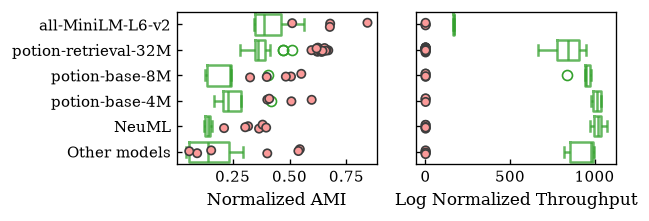

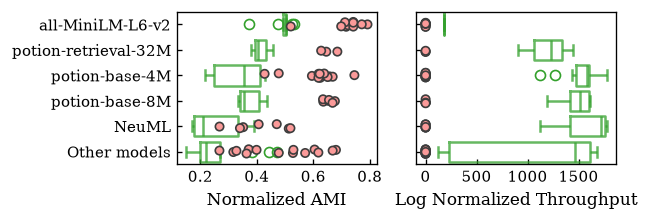

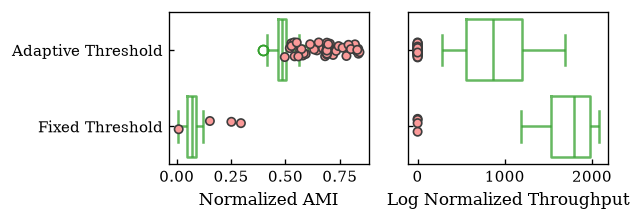

In [47]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def make_boxplots(data, data_old, algorithm, cat_column):
    df = data.copy()
    df_old = data_old.copy()
    
    df = (df
        .merge(cluster_results[["config_id", "cluster"]])
        .loc[df["algorithm"] == algorithm, ["config_id", "adj_mutual_info_final", "avg_throughput"]+[cat_column]]
        .sort_values(by="config_id"))
    
    df_sorting = (-1 * df["adj_mutual_info_final"]).argsort()
    df = df.iloc[df_sorting,:]
    
    df_old = (df_old
            .merge(cluster_results[["config_id", "cluster"]])
            .loc[df_old["algorithm"] == algorithm, ["config_id", "adj_mutual_info_final", "avg_throughput"]+[cat_column]]
            .sort_values(by="config_id"))
    
    df_old = df_old.iloc[df_sorting,:]
    
    fig, ax = plt.subplots(1,2, sharey=True, figsize=(SINGLE_COLUMN_WIDTH, PANEL_HEIGHT*0.7))
    
    df_old.loc[:,"dataset_source"] = "Test"
    df.loc[:,"dataset_source"] = "Train"  
    
    palette={
        "Train": sns.color_palette("Paired", n_colors=5)[3],
        "Test": sns.color_palette("Paired", n_colors=5)[4]
    }
    
    order = (df
             .groupby(cat_column)["adj_mutual_info_final"]
             .median()
             .sort_values(ascending=False)
             .reset_index()[cat_column])
    order = order[order.str.contains("Other").argsort()]
        
    sns.boxplot(df, x = "adj_mutual_info_final", y=cat_column, ax=ax[0], 
                color=palette["Train"], fill=False,
                boxprops={"alpha": 0.75},
                whiskerprops={"alpha": 0.75},
                capprops={"alpha": 0.75},
                medianprops={"alpha": 0.75},
                order = order
                )
    sns.stripplot(pd.concat([df_old]), x = "adj_mutual_info_final", y=cat_column, ax=ax[0], 
                hue="dataset_source", palette=palette, dodge=True, linewidth=1, size=5,
                order=order)

    sns.boxplot(df, x = "avg_throughput", y=cat_column, ax=ax[1], 
                color=palette["Train"], fill=False,
                boxprops={"alpha": 0.75},
                whiskerprops={"alpha": 0.75},
                capprops={"alpha": 0.75},
                medianprops={"alpha": 0.75},
                order = order
                )
    sns.stripplot(pd.concat([df_old]), x = "avg_throughput", y=cat_column, ax=ax[1], 
                hue="dataset_source", palette=palette, dodge=True, linewidth=1,
                order=order)

    ax[0].set_xlabel("Normalized AMI")
    ax[1].set_xlabel("Log Normalized Throughput")

    
    handles = [
        Patch(facecolor="none", edgecolor=palette["Train"], linewidth=1.5, alpha=0.75,
            label="Train"),
        Line2D([], [], marker="o", linestyle="None", markerfacecolor=palette["Test"], markeredgecolor="black", markersize=6,
            label="Test"),
    ]
    legend_fig = plt.figure()
    legend_fig.legend(handles=handles, loc="center", ncol=2)
    legend_fig.savefig(
        FIGURES_DIR / "config_analysis_train_test_legend.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0,
    )
    plt.close(legend_fig)

    for a in ax:
        a.get_legend().remove()
        a.set_ylabel("")

    fig.savefig(
        FIGURES_DIR / f"config_analysis_{algorithm}_{cat_column}.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.1,
    )

model_name_mapping = {
    "sentence_transformers_all_MiniLM_L6_v2": "all-MiniLM-L6-v2",
    "minishlab_32M": "potion-retrieval-32M",
    "minishlab_4M": "potion-base-4M",
    "minishlab_8M": "potion-base-8M",
    "NeuML" : "NeuML"
}

data = config_performance.copy()
data["model_name"] = (
    data["model"]
    .map(model_name_mapping)
    .fillna("Other models")
)

data_old = config_performance_old_datasets.copy()
data_old["model_name"] = (
    data_old["model"]
    .map(model_name_mapping)
    .fillna("Other models")
)


make_boxplots(data, data_old, "embClust", "model_name")
make_boxplots(data, data_old, "FSD", "model_name")

data = config_performance.copy()
data_old = config_performance_old_datasets.copy()

data.loc[:,"term_fading_cat"] = np.where(data["adaptive_threshold"], "Adaptive Threshold", "Fixed Threshold")
data_old.loc[:,"term_fading_cat"] = np.where(data_old["adaptive_threshold"], "Adaptive Threshold", "Fixed Threshold")

make_boxplots(data, data_old, "textClust", "term_fading_cat")

# Best trade-off configurations

In [43]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

In [44]:
config_performance = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()

# for _, group in config_performance.groupby(["dataset"]):
#     config_performance.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values

config_performance = (
    config_performance
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

display(config_performance)

,config_id,algorithm,sigma,threshold_momentum,model,time_gap,clean_interval,min_weight,window,radius,min_num_mc,use_heuristic,adaptive_threshold,decay_rate,threshold,term_fading,batch_size,cluster_interval,adj_mutual_info_final,avg_throughput
0,FSD_best_config_loo_none_seed_1.json[0],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,125.0,NaN,NaN,NaN,NaN,NaN,0.500000,NaN,8.0,NaN,0.503487,181.214255
1,FSD_best_config_loo_none_seed_1.json[1],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,116.0,NaN,NaN,NaN,NaN,NaN,0.514959,NaN,9.0,NaN,0.355797,1599.526312
2,FSD_best_config_loo_none_seed_1.json[2],FSD,NaN,NaN,minishlab_4M,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,0.306805,NaN,25.0,NaN,0.240620,1774.569121
3,FSD_best_config_loo_none_seed_1.json[3],FSD,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,0.584279,NaN,3.0,NaN,0.530846,177.225932
4,FSD_best_config_loo_none_seed_1.json[4],FSD,NaN,NaN,minishlab_8M,NaN,NaN,NaN,78.0,NaN,NaN,NaN,NaN,NaN,0.586306,NaN,29.0,NaN,0.334936,1607.658261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,0.263364,0.234695,NaN,NaN,400.0,7.137730,NaN,NaN,2.0,0.0,1.0,0.000236,NaN,1.0,NaN,4888.0,0.446343,1186.348982
142,textClust_best_config_loo_none_seed_9.json[5],textClust,0.266890,0.079436,NaN,NaN,227.0,1.938501,NaN,NaN,9.0,0.0,1.0,0.021127,NaN,1.0,NaN,4925.0,0.480818,1502.891740
143,textClust_best_config_loo_none_seed_9.json[6],textClust,0.121910,0.025919,NaN,NaN,114.0,3.097142,NaN,NaN,2.0,0.0,1.0,0.011202,NaN,0.0,NaN,4953.0,0.481441,553.207406
144,textClust_best_config_loo_none_seed_9.json[7],textClust,0.145887,0.010312,NaN,NaN,116.0,4.407335,NaN,NaN,2.0,0.0,1.0,0.011370,NaN,0.0,NaN,4957.0,0.507487,588.014341


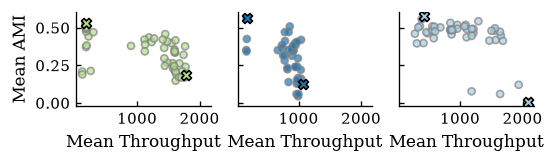

In [45]:
df = config_performance.copy()

df_best_ami_idx = (df.copy()
                    .groupby("algorithm")
                    ["adj_mutual_info_final"]
                    .idxmax()
                    )

df_best_ami = (df.copy()
               .iloc[df_best_ami_idx, :])

df_best_tp_idx = (df.copy()
                    .groupby("algorithm")
                    ["avg_throughput"]
                    .idxmax()
                    )

df_best_tp = (df.copy()
               .iloc[df_best_tp_idx, :])

def draw_panel(data, **kwargs):
    ax = plt.gca()
    alg = data["algorithm"].iloc[0]
    best_ami = df_best_ami.loc[df_best_ami["algorithm"] == alg, ["adj_mutual_info_final", "avg_throughput"]]
    best_tp = df_best_tp.loc[df_best_tp["algorithm"] == alg, ["adj_mutual_info_final", "avg_throughput"]]
    
    color = COLORS[alg]
    sns.scatterplot(data, x="avg_throughput", y="adj_mutual_info_final", 
                    size=1,facecolor=color, linewidth=1, edgecolor="grey", alpha=0.7, ax=ax)
    plt.scatter(
        y=best_ami["adj_mutual_info_final"],
        x=best_ami["avg_throughput"],
        color=color,
        edgecolors="black",
        zorder=3,
        marker="X"
    )
    plt.scatter(
        y=best_tp["adj_mutual_info_final"],
        x=best_tp["avg_throughput"],
        color=color,
        edgecolors="black",
        zorder=3,
        marker="X"
    )
    

g = sns.FacetGrid(df, col="algorithm", height=PANEL_HEIGHT*0.7, aspect=facet_aspect(len(ALGORITHM_ORDER),height=PANEL_HEIGHT*0.7))
g.map_dataframe(draw_panel)
g.set_titles(col_template="")
g.set_xlabels("Mean Throughput")
g.set_ylabels("Mean AMI")

legend_handles: list[Patch | Line2D] = [
    Patch(facecolor=COLORS[alg], label=alg, edgecolor="black") for alg in ALGORITHM_ORDER
]
legend_handles.append(
    Line2D(
        [],
        [],
        marker="X",
        linestyle="None",
        markerfacecolor="grey",
        markeredgecolor="black",
        label="Selected configuration",
        markersize=8,
    )
)
legend_fig = plt.figure()
legend_fig.legend(handles=legend_handles, loc="center", ncol=4)
legend_fig.savefig(
    FIGURES_DIR / "config_analysis_best_tradeoff_legend.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0,
)
plt.close(legend_fig)


g.figure.savefig(
    FIGURES_DIR / "config_analysis_best_tradeoff.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)

plt.show()

In [46]:
df_ami = df_best_ami.copy()
df_tp = df_best_tp.copy()

hyperparameter_order=[ 
    'adaptive_threshold',
    'sigma',
    'radius',
    'use_heuristic',
    'time_gap',
    'min_weight',
    'decay_rate',
    'threshold_momentum',
    'min_num_mc',
    'clean_interval', 'cluster_interval',
    'term_fading',
    'model', 'threshold', 'window', 'batch_size'
]

hyperparameter_types={
    'adaptive_threshold':bool,
    'sigma':float,
    'radius':float,
    'use_heuristic':bool,
    'time_gap':float,
    'min_weight':float,
    'decay_rate':float,
    'threshold_momentum':float,
    'min_num_mc':int,
    'clean_interval':int, 
    'cluster_interval':int,
    'term_fading':bool,
    'model':str, 
    'threshold':float, 
    'window':int, 
    'batch_size':int

}

hyperparameter_names={
    'adaptive_threshold':"Adaptive Threshold",
    'sigma':"Sigma",
    'radius':"Radius",
    'use_heuristic':"Min. Weight Heuristic",
    'time_gap':"Time Gap",
    'min_weight':"Min. Weight",
    'decay_rate':"Decay Rate",
    'threshold_momentum':"Thresh. Momentum",
    'min_num_mc':"Min. \\#Microclusters",
    'clean_interval':"Clean Interval", 
    'cluster_interval':"Cluster Interval",
    'term_fading':"Term Fading",
    'model':"Emb. model", 
    'threshold':"Threshold", 
    'window':"Window Size", 
    'batch_size':"Batch Size"
}

str_renames = {
    "sentence_transformers_all_MiniLM_L6_v2": "ST",
    "NeuML" : "NML"
}


def prep_dataset(df):
    df = df.drop(columns=['config_id'])
    
    bool_cols = [n for n,t in hyperparameter_types.items() if t == bool]
    int_cols = [n for n,t in hyperparameter_types.items() if t == int]
    float_cols = [n for n,t in hyperparameter_types.items() if t == float]
    
    for col in bool_cols:
        df[col] = df[col].map({1.0: "on", 0.0: "off"}).fillna("-")
        
    for col in int_cols:
        df[col] = df[col].astype("Int64")
        
    for col in float_cols:
        df[col] = df[col].map(
            lambda value: f"{value:.4f}" if pd.notna(value) else value
        )
        
    df = df.replace(str_renames)
    
    df.index = df["algorithm"]
    df = df.drop(columns=["algorithm"]).transpose()

    df = df.fillna("-")
    df = df.loc[hyperparameter_order, :]
    df = df.rename(index=hyperparameter_names)
    return df

pretty_ami = prep_dataset(df_ami)
pretty_tp = prep_dataset(df_tp)

pretty_combined = pd.concat({"Best AMI": pretty_ami, "Best Throughput": pretty_tp}, axis=1)
pretty_combined.columns = pretty_combined.columns.set_names([None, None])
display(pretty_combined)

latex_table = pretty_combined.style.to_latex(
    column_format="l|ccc|ccc", multicol_align="c",
    label="tab:best_configs_selection",
    caption="Best trade-off configurations per algorithm. '-' indicates that a hyperparameter is not applicable. 'ST' and 'NML' stand for sentence-transformers/all-MiniLM-L6-v2 and NeuML/pubmedbert-base-embeddings-2M, respectively.")

latex_table = latex_table.replace(
    "\\begin{tabular}",
    "\\resizebox{\\columnwidth}{!}{%\n\\begin{tabular}",
    1,
)
latex_table = latex_table.replace(
    "\\end{tabular}",
    "\\end{tabular}%\n}",
    1,
)

print(latex_table)
(LATEX_DIR / "best_configurations.tex").write_text(
    latex_table,
    encoding="utf-8",
)

Best AMI                    Best Throughput           \
                           FSD embClust textClust             FSD embClust   
Adaptive Threshold           -       on        on               -      off   
Sigma                        -   1.4982    0.3512               -        -   
Radius                       -        -         -               -   0.3304   
Min. Weight Heuristic        -      off       off               -      off   
Time Gap                     -        -         -               -        -   
Min. Weight                  -   5.9549    0.3283               -   1.3209   
Decay Rate                   -   0.0088    0.0092               -   0.0315   
Thresh. Momentum             -   0.1168    0.5580               -        -   
Min. \#Microclusters         -        1         3               -       28   
Clean Interval               -      300       353               -      114   
Cluster Interval             -      553      2463               -     4207   
Term Fading                  -        -       off               -        -   
Emb. model                  ST       ST         -             NML      NML   
Threshold               0.5843        -         -          0.8391        -   
Window Size                 76        -         -              62        -   
Batch Size                   3        -         -              88        -   

                                 
                      textClust  
Adaptive Threshold          off  
Sigma                         -  
Radius                   0.1964  
Min. Weight Heuristic       off  
Time Gap                      -  
Min. Weight              6.5888  
Decay Rate               0.0030  
Thresh. Momentum              -  
Min. \#Microclusters         10  
Clean Interval               21  
Cluster Interval           1329  
Term Fading                 off  
Emb. model                    -  
Threshold                     -  
Window Size                   -  
Batch Size                    -

\begin{table}
\caption{Best trade-off configurations per algorithm. '-' indicates that a hyperparameter is not applicable. 'ST' and 'NML' stand for sentence-transformers/all-MiniLM-L6-v2 and NeuML/pubmedbert-base-embeddings-2M, respectively.}
\label{tab:best_configs_selection}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{l|ccc|ccc}
 & \multicolumn{3}{c}{Best AMI} & \multicolumn{3}{c}{Best Throughput} \\
 & FSD & embClust & textClust & FSD & embClust & textClust \\
Adaptive Threshold & - & on & on & - & off & off \\
Sigma & - & 1.4982 & 0.3512 & - & - & - \\
Radius & - & - & - & - & 0.3304 & 0.1964 \\
Min. Weight Heuristic & - & off & off & - & off & off \\
Time Gap & - & - & - & - & - & - \\
Min. Weight & - & 5.9549 & 0.3283 & - & 1.3209 & 6.5888 \\
Decay Rate & - & 0.0088 & 0.0092 & - & 0.0315 & 0.0030 \\
Thresh. Momentum & - & 0.1168 & 0.5580 & - & - & - \\
Min. \#Microclusters & - & 1 & 3 & - & 28 & 10 \\
Clean Interval & - & 300 & 353 & - & 114 & 21 \\
Cluster Interval & - & 553 &

1270

In [16]:
#TODO: Plots on number of clusters
#TODO: Why is embClust so bad on MMD
#TODO: Report two trade-off configurations per algorithm